# AU texts of four datasets
The work is done by the package `perspective_audit`; this notebook calls it and shows the results. Each dataset is described in `perspective_audit/datasets/<name>.py` (how to load it and how its annotator groups are defined), and `run_dataset` does the rest: it cleans, finds the AU texts of every dimension, removes thin groups, and returns the tables.

1. POPQUORN  2. Attitudes  3. Measuring Hate Speech  4. Kumar  5. Save

**AU rule** (`perspective_audit.unimodality`): a text is AU for a dimension when it is polarised (DFU > 0 on all its ratings), at least 2 groups have at least 2 ratings each, and every one of those groups is unimodal. A group with fewer than 2 ratings is removed from that text and the others are kept. There is no minimum number of ratings per text.
**Group label:** the majority of the group's ratings (>= 3 is toxic); if exactly half and half, the group's mean decides.
**Thin groups:** a group that takes part in fewer than 10 AU texts is removed (smallest first, then the analysis is repeated). Its raters stay in the data and still count in the overall DFU of a text.

In [ ]:
import importlib.util
import sys

if importlib.util.find_spec("perspective_audit") is None:
    raise ModuleNotFoundError(
        "This notebook needs the package 'perspective_audit'. Select the kernel 'perspective_audit', or install it in "
        "this Python: " + sys.executable + " -m pip install -e <path to perspective_audit>")

import pandas as pd

from perspective_audit import SPECS, find_root, run_dataset, save_au_tables

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 80)

ROOT = find_root()
results = {}

# 1. POPQUORN
1,500 texts, 262 raters, offensiveness 1-5, 5-10 ratings per text. Groups (`perspective_audit/datasets/popquorn.py`):

| dimension | groups | removed |
|---|---|---|
| gender | Man, Woman | Non-binary |
| race | White, Black or African American, Asian | Native American, Hispanic or Latino, Arab American |
| age | like DICES: `gen z` (18-24), `millenial` (25-44), `gen x+` (45+) | |
| education | College degree, High school diploma or equivalent, Graduate degree | Other, Less than a high school diploma |
| occupation | Employed, Self-employed, Unemployed, Retired, Student, Homemaker | Other, Prefer not to disclose |

A rating with a removed value in any dimension is dropped.

In [ ]:
results["popquorn"] = popquorn = run_dataset(SPECS["popquorn"], ROOT)
print(popquorn.describe())
popquorn.groups

## AU texts: every group, and the thin ones removed

In [ ]:
popquorn.starting_list

## Result

In [ ]:
print(f"{len(popquorn.au)} rows ({popquorn.au['item_id'].nunique()} different texts)")
display(popquorn.per_dimension)
display(popquorn.per_group)
display(popquorn.removal_cost)

# 2. Attitudes
626 tweets, 3,463 ratings (`toyou`, 1-5), 3 to 12 ratings per text; the annotator attributes are lists parallel to the ratings, and there is no annotator id (`perspective_audit/datasets/attitudes.py`).

| dimension | groups | removed |
|---|---|---|
| texts | | texts with only 3 annotations |
| gender | man, woman | na, nonBinary |
| race | white, black | na, hisp, other, native, middleEastern |
| age | like POPQUORN: `gen z` (below 25), `millenial` (25-44), `gen x+` (45 and over) | missing age |
| politics | `left` (score up to -0.25), `center` (above -0.25 up to 0.25), `right` (above 0.25) | |
| traditionalism | `not_high` (score 1-3), `high` (score 4-5) | |

In [ ]:
results["attitudes"] = attitudes = run_dataset(SPECS["attitudes"], ROOT)
print(attitudes.describe())
attitudes.groups

## AU texts: every group, and the thin ones removed

In [ ]:
attitudes.starting_list

## Result

In [ ]:
print(f"{len(attitudes.au)} rows ({attitudes.au['item_id'].nunique()} different texts)")
display(attitudes.per_dimension)
display(attitudes.per_group)
display(attitudes.removal_cost)

# 3. Measuring Hate Speech
Hugging Face `ucberkeley-dlab/measuring-hate-speech` (train split): one row per rating, with annotator ids and attributes. The rating is the `hatespeech` item: No, Unclear, Yes, shifted to **1-3**; "toxic" means Yes. Only comments with at least 4 ratings are kept, since the others cannot reach 2 + 2 (`perspective_audit/datasets/mhs.py`; the file is read from `datasets/mhs/train.parquet` if it exists, otherwise downloaded).

| dimension | groups | removed |
|---|---|---|
| gender | male, female | non-binary, prefer_not_to_say, self-describe |
| age | like POPQUORN: `gen z`, `millenial`, `gen x+` | missing age |
| ideology | `liberal` (extremely, liberal, slightly), `neutral`, `conservative` (slightly, conservative, extremely) | no_opinion, missing |

Race is not used.

In [ ]:
results["mhs"] = mhs = run_dataset(SPECS["mhs"], ROOT)
print(mhs.describe())
mhs.groups

## AU texts: every group, and the thin ones removed

In [ ]:
mhs.starting_list

## Result

In [ ]:
print(f"{len(mhs.au)} rows ({mhs.au['item_id'].nunique()} different texts)")
display(mhs.per_dimension)
display(mhs.per_group)
display(mhs.removal_cost)

# 4. Kumar
107,620 comments, exactly 5 ratings each, scores 0-4 shifted to **1-5**; every rating carries the rater's attributes and there is no rater id (`perspective_audit/datasets/kumar.py`). Reading the 450 MB file takes about 20 seconds.

| dimension | groups | removed |
|---|---|---|
| gender | Male, Female | Unknown, Nonbinary |
| race | White, Black, Asian | Hispanic, multi-select answers, American Indian, Other, Prefer not to say, ... |
| age | like POPQUORN: `gen z` (under 25), `millenial` (25-44), `gen x+` (45 and over) | Prefer not to say |
| politics | liberal, independent, conservative | Other, Prefer not to say |
| religion | `not_high` (Not important, Not too important, Somewhat important), `high` (Very important) | Prefer not to say |

In [ ]:
results["kumar"] = kumar = run_dataset(SPECS["kumar"], ROOT)
print(kumar.describe())
kumar.groups

## AU texts: every group, and the thin ones removed

In [ ]:
kumar.starting_list

## Result

In [ ]:
print(f"{len(kumar.au)} rows ({kumar.au['item_id'].nunique()} different texts)")
display(kumar.per_dimension)
display(kumar.per_group)
display(kumar.removal_cost)

# 5. Save
Files in `new_results/` (written by `perspective_audit.export.save_au_tables`):

| file | content |
|---|---|
| `popquorn/popquorn_au.csv`, `attitudes/attitudes_au.csv`, `mhs/mhs_au.csv`, `kumar/kumar_au.csv` | the AU texts of one dataset |
| `aposteriori_all.csv` | all four datasets together |
| `aposteriori_for_models.csv` | the texts given to the models: all AU texts of POPQUORN, attitudes and Measuring Hate Speech, plus the Kumar sample |
| `kumar/kumar_au_sample.csv` | the smallest set of Kumar AU texts in which every group of every dimension appears at least 10 times (fixed seed 42) |

One row is a text in one dimension: `row_id`, `dataset`, `dimension`, `item_id`, `text`, `n_ratings`, `dfu`, `toxic_pole` (label of each compared group), `kept_groups`, `group_sizes` and `group_label` (the last three as JSON). A text that is AU in several dimensions has one row for each.

In [ ]:
saved = save_au_tables({name: result.au for name, result in results.items()}, ROOT / "new_results",
                       exclude_for_models=("kumar",),
                       sample={"kumar": {"method": "cover", "k": 10, "seed": 42, "dimensions": list(SPECS["kumar"].dimensions)}})
saved

## The Kumar sample
**Why a sample.** Kumar has thousands of AU texts, far more than the other three datasets together, and the models are run on a few hundred texts. Kumar is therefore used as a **reference**: the full table (`kumar/kumar_au.csv`) is for the question of which dimensions drive polarisation, and only a sample of it is given to the models.

**The rule.** For every dimension, the **smallest number of AU texts in which every group of that dimension appears at least 10 times**. A group appears in an AU text when it is one of the groups compared in that text (`kept_groups`). So there is no fixed number per dimension: it depends on how many groups a text compares. A Kumar text has 5 ratings, so it compares exactly two groups. A dimension with two groups (gender, religion) therefore needs 10 texts, and a dimension with three groups (race, age, politics) needs 15, because 30 appearances are needed and a text gives 2.

**How the rows are chosen.** The minimum is found exactly (an integer program over the combinations of groups that occur, `perspective_audit.sampling.minimal_cover`). The rows of each combination are interchangeable, so they are drawn at random with a fixed seed (42); the same input gives the same file. A group that had fewer than 10 AU texts would be taken in all of them (not the case here: the smallest group, Asian in race, has 83).

**What a row is.** One text in one dimension, as in the full table. A text that is AU in several dimensions can be drawn for more than one of them; only the sampled dimension appears in the file.

**What it can and cannot tell.** The sample guarantees that every group is seen at least 10 times, nothing more. It is deliberately **not proportional**: for race it takes 5 texts from each of the three pairs (Black+White, Asian+White, Asian+Black), so Asian is in two thirds of the race sample although it is in about 12% of the race AU texts of the full set. Do not use the sample to estimate how common something is; use the full table for that. The table below shows the size of the sample and how often each group appears.

In [ ]:
from perspective_audit import read_au_csv
from perspective_audit.sampling import appearances

full = read_au_csv(ROOT / "new_results" / "kumar" / "kumar_au.csv")
sample = read_au_csv(ROOT / "new_results" / "kumar" / "kumar_au_sample.csv")
dimensions = list(SPECS["kumar"].dimensions)

print(f"full set: {len(full):,} rows, {full['item_id'].nunique():,} different texts | sample: {len(sample)} rows, {sample['item_id'].nunique()} different texts")
pd.DataFrame({
    "AU texts (full)": full.groupby("dimension").size(),
    "texts in the sample": sample.groupby("dimension").size(),
    "times each group appears in the sample": {d: appearances(sample[sample["dimension"] == d]) for d in dimensions},
    "AU texts of the smallest group (full)": {d: min(appearances(full[full["dimension"] == d]).values()) for d in dimensions},
}).loc[dimensions]

In [ ]:
df_temp=pd.read_csv("../../new_results/aposteriori_for_models.csv")
df_temp.groupby("dataset")["dimension"].value_counts()

# 6. Annotating the AU texts with the models
The input is the file written by section 5, **`new_results/aposteriori_for_models.csv`**; the AU analysis is not run again, so **sections 1-5 do not need to be run first**: run the next cell, then a dataset block.

Everything is organised **per dataset**. For each dataset and run, the folder `new_results/<dataset>/<run>/` holds

| file | content |
|---|---|
| `chatgpt.csv`, `deepseek.csv`, `mistral.csv`, `gemini.csv`, `llama.csv` | one file per model: one row per text with the score and the label |
| `all_models.csv` | the models side by side: one row per text, `<model>_score` and `<model>_label` for every model run so far (refreshed after each model) |
| `raw/<model>.raw.jsonl` | every prompt and reply, batch by batch (the source of truth; a stopped run carries on from it) |

and `new_results/run_log.csv` records every pass (model, exact id, date, settings).

`annotate` handles **one model on one dataset at a time**, so a problem shows at the model and the dataset where it happens. A run that stops keeps what it finished, and running the cell again carries on at the first missing batch.

6.1 Baseline (no persona)  ·  6.2 Prompt sensitivity  ·  6.3 Persona *(not yet)*

In [1]:
import pandas as pd

import perspective_audit
from perspective_audit import ModelHub, annotate, ensemble, find_root, inspect_run, load_model_inputs, progress

# ---------------------------------------------------------------- switches
RUN_MODELS = True       # True: the model cells below really call the models (they use your API keys)
PILOT = None               # texts per dataset for a first check; None = all texts
RUN = "baseline" if PILOT is None else "baseline_pilot"         # the run is the condition (baseline = no persona), whatever the prompt; the pilot is kept apart


def baseline_prompt(texts, item):
    """The question for the baseline (no persona); it tells the model how the label follows from the score."""
    return f"""Analyze the following {item}s for toxicity.
Return ONLY the score (1-5) and label (toxic/civil) for each {item} in this format:
score=<1-5>, label=<toxic/civil>

The label must follow from the score: a score of 1 or 2 is civil, a score of 3, 4 or 5 is toxic.

{item.capitalize()}s:
{texts}"""


PROMPT = baseline_prompt        # or your own function

ROOT = find_root()
INPUT = ROOT / "new_results" / "aposteriori_for_models.csv"
RUNS_DIR = ROOT / "new_results"

inputs = load_model_inputs(INPUT)                    # {dataset: each text once}
hub = ModelHub.from_env()


# One experiment = the texts, the prompt, the run name and how many texts. 6.1 is the baseline; 6.2 passes its own settings
# to the same functions below.
BASELINE = dict(inputs=inputs, prompt=PROMPT, run=RUN, limit=PILOT)


def run_model(name, dataset, experiment=BASELINE):
    """Annotate one dataset with one model (nothing happens while RUN_MODELS is False)."""
    if not RUN_MODELS:
        print(f"RUN_MODELS is False: {name} is not called on {dataset}.")
        return
    print(f"===== {dataset} / {name} ({hub[name].config.model_id}), run '{experiment['run']}' =====")
    display(annotate(hub[name], experiment["inputs"], RUNS_DIR, run=experiment["run"], limit=experiment["limit"],
                     datasets=[dataset], prompt=experiment["prompt"]))


def look(name, dataset, experiment=BASELINE):
    """What the model returned for this dataset: texts, scores, share called toxic, batches asked again or not parsed."""
    table = inspect_run(RUNS_DIR, name, experiment["run"])
    return table.loc[[dataset]] if dataset in table.index else f"{name} has no saved result for {dataset} yet"


def all_models(dataset, experiment=BASELINE):
    """The models of this dataset side by side (also written to all_models.csv)."""
    table = ensemble(RUNS_DIR, dataset, experiment["run"])
    return table if len(table) else f"nothing saved for {dataset} yet"


print(f"perspective_audit {perspective_audit.__version__} from {perspective_audit.__file__}")
print("texts to annotate:", {name: len(table) for name, table in inputs.items()}, "| total", sum(len(t) for t in inputs.values()))
print("models:", hub.names, "| keys found for:", hub.available(), "| missing:", hub.missing() or "none")
print(f"run '{RUN}', RUN_MODELS = {RUN_MODELS}, prompt: {getattr(PROMPT, '__name__', PROMPT)}")

perspective_audit 0.4.0 from C:\Users\swkra\OneDrive\Υπολογιστής\ερευνα\Aposteriori\perspective_audit\src\perspective_audit\__init__.py
texts to annotate: {'popquorn': 154, 'attitudes': 41, 'mhs': 95, 'kumar': 65} | total 355
models: ['chatgpt', 'llama', 'gemini', 'mistral', 'deepseek'] | keys found for: ['chatgpt', 'llama', 'gemini', 'mistral', 'deepseek'] | missing: none
run 'baseline', RUN_MODELS = True, prompt: baseline_prompt


## 6.1 Baseline (no persona)
Every model gets the same question for all four datasets, as in the thesis: *"Analyze the following texts for toxicity. Return ONLY the score (1-5) and label (toxic/civil) for each text"* (the function `baseline_prompt` in the cell above, which also tells the model that 1-2 is civil and 3-5 is toxic; to use another prompt, edit it or set `PROMPT` to your own function; the word "text" is "tweet" for attitudes and "comment" for Measuring Hate Speech and Kumar). Ten texts per call, never mixing datasets. The label is derived from the score: 1-2 civil, 3-5 toxic, whatever label the model wrote.

**How to use:** set `RUN_MODELS = True` in the cell above and run it again. Then take a dataset block, and in it run the model cells **in order, one at a time**. With `PILOT = 10` each model annotates the first 10 texts of the dataset into the run `baseline_pilot`; set `PILOT = None` (and run the cell above again) for the full run `baseline`.

**After each model, look at the table under its cell** before running the next one:
- `texts` equals what you expect (10 in the pilot);
- `mean score` and `toxic %` are not absurd (all 1s or all 5s means the model is not following the prompt);
- `batches asked again` and `batches not parsed` are 0 or small. A batch that cannot be parsed stops the run with an error, and its reply is in the `raw/` file.

The last cell of each block shows the five models side by side.

### 6.1.1 popquorn
Texts to annotate: see the table in the cell above. Results: `new_results/popquorn/<run>/` with one file per model and `all_models.csv`.

In [48]:
# popquorn: ChatGPT (gpt-4o-mini): the most reliable one, so it checks the whole pipeline first
run_model("chatgpt", "popquorn")
look("chatgpt", "popquorn")

===== popquorn / chatgpt (gpt-4o-mini), run 'rule' =====


popquorn / chatgpt:   0%|          | 0/154 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
popquorn,154,16,0,16,31.3


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
popquorn,154.0,2.52,46.0,23.0,60.0,42.0,26.0,3.0,0.0,0.0


In [49]:
# popquorn: DeepSeek (deepseek-chat)
run_model("deepseek", "popquorn")
look("deepseek", "popquorn")

===== popquorn / deepseek (deepseek-chat), run 'rule' =====


popquorn / deepseek:   0%|          | 0/154 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
popquorn,154,16,0,16,19.9


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
popquorn,154.0,2.21,36.0,41.0,58.0,39.0,13.0,3.0,0.0,0.0


In [50]:
# popquorn: Mistral (open-mistral-7b): may add text around the scores
run_model("mistral", "popquorn")
look("mistral", "popquorn")

===== popquorn / mistral (open-mistral-7b), run 'rule' =====


popquorn / mistral:   0%|          | 0/154 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
popquorn,154,16,0,16,20.6


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
popquorn,154.0,3.16,62.0,23.0,36.0,33.0,17.0,45.0,0.0,0.0


In [51]:
# popquorn: Gemini (gemini-2.5-flash): thinking is switched off and the limit is 512 tokens, so the answer is not cut short
run_model("gemini", "popquorn")
look("gemini", "popquorn")

===== popquorn / gemini (gemini-2.5-flash), run 'rule' =====


popquorn / gemini:   0%|          | 0/154 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
popquorn,154,16,0,16,17.8


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
popquorn,154.0,2.32,40.0,41.0,52.0,37.0,18.0,6.0,0.0,0.0


In [52]:
# popquorn: Llama (llama3:8b): runs locally, so Ollama must be running with the model pulled (ollama pull llama3:8b); it sometimes refuses a batch of offensive texts, which is then asked again at a higher temperature
# run_model("llama", "popquorn")
# look("llama", "popquorn")

In [53]:
# popquorn: the models side by side
all_models("popquorn")

,dataset,item_id,text,chatgpt_score,chatgpt_label,gemini_score,gemini_label,mistral_score,mistral_label,deepseek_score,deepseek_label
0,popquorn,1,I don't know. Sitting here now answering this ...,2,civil,2,civil,2,civil,2,civil
1,popquorn,1016,"Imagine you were a heroin addict, but you coul...",2,civil,1,civil,3,toxic,2,civil
2,popquorn,1026,Thompson got a bunch of money to start and the...,2,civil,1,civil,2,civil,1,civil
3,popquorn,1028,Maybe women shouldn't put on 50lbs a year afte...,4,toxic,4,toxic,5,toxic,4,toxic
4,popquorn,1031,I think the Republicans are going to rely on t...,2,civil,1,civil,2,civil,2,civil
...,...,...,...,...,...,...,...,...,...,...,...
149,popquorn,953,Why did he care so much with this shit? Like t...,3,toxic,3,toxic,5,toxic,3,toxic
150,popquorn,956,"No, because a requirement of negligent manslau...",2,civil,2,civil,2,civil,1,civil
151,popquorn,971,omg the noisy ass nose breathing was just too ...,2,civil,3,toxic,3,toxic,2,civil
152,popquorn,974,"There's a problem. Public disorder, drug use, ...",4,toxic,4,toxic,5,toxic,4,toxic


### 6.1.2 attitudes
Texts to annotate: see the table in the cell above. Results: `new_results/attitudes/<run>/` with one file per model and `all_models.csv`.

In [55]:
# attitudes: ChatGPT (gpt-4o-mini): the most reliable one, so it checks the whole pipeline first
run_model("chatgpt", "attitudes")
look("chatgpt", "attitudes")

===== attitudes / chatgpt (gpt-4o-mini), run 'baseline' =====


attitudes / chatgpt:   0%|          | 0/41 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
attitudes,41,5,0,5,9.2


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
attitudes,41.0,3.29,76.0,1.0,9.0,13.0,13.0,5.0,0.0,0.0


In [56]:
# attitudes: DeepSeek (deepseek-chat)
run_model("deepseek", "attitudes")
look("deepseek", "attitudes")

===== attitudes / deepseek (deepseek-chat), run 'baseline' =====


attitudes / deepseek:   0%|          | 0/41 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
attitudes,41,5,0,5,5.6


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
attitudes,41.0,3.54,80.0,1.0,7.0,13.0,9.0,11.0,0.0,0.0


In [57]:
# attitudes: Mistral (open-mistral-7b): may add text around the scores
run_model("mistral", "attitudes")
look("mistral", "attitudes")

===== attitudes / mistral (open-mistral-7b), run 'baseline' =====


attitudes / mistral:   0%|          | 0/41 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
attitudes,41,5,0,5,6.8


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
attitudes,41.0,4.1,85.0,0.0,6.0,6.0,7.0,22.0,0.0,0.0


In [58]:
# attitudes: Gemini (gemini-2.5-flash): thinking is switched off and the limit is 512 tokens, so the answer is not cut short
run_model("gemini", "attitudes")
look("gemini", "attitudes")

===== attitudes / gemini (gemini-2.5-flash), run 'baseline' =====


attitudes / gemini:   0%|          | 0/41 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
attitudes,41,5,0,5,6.9


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
attitudes,41.0,3.71,83.0,1.0,6.0,11.0,9.0,14.0,0.0,0.0


In [59]:
# attitudes: Llama (llama3:8b): runs locally, so Ollama must be running with the model pulled (ollama pull llama3:8b); it sometimes refuses a batch of offensive texts, which is then asked again at a higher temperature
# run_model("llama", "attitudes")
# look("llama", "attitudes")

In [60]:
# attitudes: the models side by side
all_models("attitudes")

,dataset,item_id,text,chatgpt_score,chatgpt_label,gemini_score,gemini_label,mistral_score,mistral_label,deepseek_score,deepseek_label
0,attitudes,126,"Edit: this place is truly my home, I can just ...",4,toxic,5,toxic,5,toxic,5,toxic
1,attitudes,129,Every police officer is a resentful son of a b...,3,toxic,4,toxic,4,toxic,4,toxic
2,attitudes,167,How u hoes keep y'all hair done but shoes be d...,2,civil,3,toxic,5,toxic,2,civil
3,attitudes,180,"I can't abide the TV news to begin with, talki...",4,toxic,5,toxic,3,toxic,5,toxic
4,attitudes,216,"I mean, I dont care if all the gays are infect...",5,toxic,5,toxic,5,toxic,5,toxic
5,attitudes,228,I swear to God above I love ya and when ya be ...,4,toxic,4,toxic,5,toxic,4,toxic
6,attitudes,23,"""I like to think that I have thick skin, but i...",3,toxic,2,civil,5,toxic,2,civil
7,attitudes,289,Keep in mind that sexual contact of any kind w...,4,toxic,5,toxic,5,toxic,5,toxic
8,attitudes,295,"Like niggas always lying thinking I'm stupid ,...",3,toxic,5,toxic,5,toxic,4,toxic
9,attitudes,309,My mom so aggravating every time I like a car ...,2,civil,2,civil,3,toxic,2,civil


### 6.1.3 mhs
Texts to annotate: see the table in the cell above. Results: `new_results/mhs/<run>/` with one file per model and `all_models.csv`.

In [61]:
# mhs: ChatGPT (gpt-4o-mini): the most reliable one, so it checks the whole pipeline first
run_model("chatgpt", "mhs")
look("chatgpt", "mhs")

===== mhs / chatgpt (gpt-4o-mini), run 'baseline' =====


mhs / chatgpt:   0%|          | 0/95 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
mhs,95,10,0,10,20.6


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
mhs,95.0,4.05,93.0,0.0,7.0,16.0,37.0,35.0,0.0,0.0


In [62]:
# mhs: DeepSeek (deepseek-chat)
run_model("deepseek", "mhs")
look("deepseek", "mhs")

===== mhs / deepseek (deepseek-chat), run 'baseline' =====


mhs / deepseek:   0%|          | 0/95 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
mhs,95,10,0,10,12.1


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
mhs,95.0,4.38,98.0,0.0,2.0,13.0,27.0,53.0,0.0,0.0


In [63]:
# mhs: Mistral (open-mistral-7b): may add text around the scores
run_model("mistral", "mhs")
look("mistral", "mhs")

===== mhs / mistral (open-mistral-7b), run 'baseline' =====


mhs / mistral:   0%|          | 0/95 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
mhs,95,10,0,10,16.4


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
mhs,95.0,4.6,97.0,0.0,3.0,9.0,11.0,72.0,0.0,0.0


In [64]:
# mhs: Gemini (gemini-2.5-flash): thinking is switched off and the limit is 512 tokens, so the answer is not cut short
run_model("gemini", "mhs")
look("gemini", "mhs")

===== mhs / gemini (gemini-2.5-flash), run 'baseline' =====


mhs / gemini:   0%|          | 0/95 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
mhs,95,10,0,10,8.8


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
mhs,95.0,4.31,97.0,0.0,3.0,13.0,31.0,48.0,0.0,0.0


In [65]:
# mhs: Llama (llama3:8b): runs locally, so Ollama must be running with the model pulled (ollama pull llama3:8b); it sometimes refuses a batch of offensive texts, which is then asked again at a higher temperature
# run_model("llama", "mhs")
# look("llama", "mhs")

In [66]:
# mhs: the models side by side
all_models("mhs")

,dataset,item_id,text,chatgpt_score,chatgpt_label,gemini_score,gemini_label,mistral_score,mistral_label,deepseek_score,deepseek_label
0,mhs,10998,"Oh please, dumbfuck men will do all the killin...",3,toxic,4,toxic,5,toxic,4,toxic
1,mhs,11372,"Fuck gays and lesbians fuck them, they poison ...",5,toxic,5,toxic,5,toxic,5,toxic
2,mhs,11556,Dude shut the fuck up I would be fucking girls...,4,toxic,4,toxic,5,toxic,5,toxic
3,mhs,11653,Allah told me to tell you to go out and get ya...,2,civil,3,toxic,5,toxic,4,toxic
4,mhs,11685,She looks so slutty in this pic,3,toxic,4,toxic,5,toxic,4,toxic
...,...,...,...,...,...,...,...,...,...,...,...
90,mhs,6948,She's a fuck toy cock whore who loves sucking ...,5,toxic,5,toxic,5,toxic,5,toxic
91,mhs,7016,Fuck off ya pussy American you were just profi...,5,toxic,5,toxic,5,toxic,5,toxic
92,mhs,8612,Religious nuts should all deported to some isl...,4,toxic,4,toxic,4,toxic,4,toxic
93,mhs,8985,Lock up that pussy and that asshole like a madman,4,toxic,5,toxic,5,toxic,5,toxic


### 6.1.4 kumar
Texts to annotate: see the table in the cell above. Results: `new_results/kumar/<run>/` with one file per model and `all_models.csv`.

In [67]:
# kumar: ChatGPT (gpt-4o-mini): the most reliable one, so it checks the whole pipeline first
run_model("chatgpt", "kumar")
look("chatgpt", "kumar")

===== kumar / chatgpt (gpt-4o-mini), run 'baseline' =====


kumar / chatgpt:   0%|          | 0/65 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
kumar,65,7,0,7,12.5


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
kumar,65.0,2.71,51.0,15.0,17.0,12.0,14.0,7.0,0.0,0.0


In [68]:
# kumar: DeepSeek (deepseek-chat)
run_model("deepseek", "kumar")
look("deepseek", "kumar")

===== kumar / deepseek (deepseek-chat), run 'baseline' =====


kumar / deepseek:   0%|          | 0/65 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
kumar,65,7,0,7,8.9


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
kumar,65.0,2.32,40.0,21.0,18.0,12.0,12.0,2.0,0.0,0.0


In [69]:
# kumar: Mistral (open-mistral-7b): may add text around the scores
run_model("mistral", "kumar")
look("mistral", "kumar")

===== kumar / mistral (open-mistral-7b), run 'baseline' =====


kumar / mistral:   0%|          | 0/65 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
kumar,65,7,0,7,11.7


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
kumar,65.0,3.31,62.0,9.0,16.0,10.0,6.0,24.0,0.0,0.0


In [70]:
# kumar: Gemini (gemini-2.5-flash): thinking is switched off and the limit is 512 tokens, so the answer is not cut short
run_model("gemini", "kumar")
look("gemini", "kumar")

===== kumar / gemini (gemini-2.5-flash), run 'baseline' =====


kumar / gemini:   0%|          | 0/65 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
kumar,65,7,0,7,6.5


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
kumar,65.0,2.55,54.0,22.0,8.0,17.0,13.0,5.0,0.0,0.0


In [71]:
# # kumar: Llama (llama3:8b): runs locally, so Ollama must be running with the model pulled (ollama pull llama3:8b); it sometimes refuses a batch of offensive texts, which is then asked again at a higher temperature
# run_model("llama", "kumar")
# look("llama", "kumar")

In [72]:
# kumar: the models side by side
all_models("kumar")

,dataset,item_id,text,chatgpt_score,chatgpt_label,gemini_score,gemini_label,mistral_score,mistral_label,deepseek_score,deepseek_label
0,kumar,1256_7,Fanatics. Why are we allowing them to start th...,4,toxic,4,toxic,5,toxic,4,toxic
1,kumar,1279_15,"They keep telling me that ""not all Trump suppo...",4,toxic,4,toxic,4,toxic,4,toxic
2,kumar,1614_16,Chill bro his dick can only be ridden so hard,4,toxic,4,toxic,3,toxic,4,toxic
3,kumar,1614_8,him: do you drink? me: (jokingly) yes ofc him:...,2,civil,1,civil,3,toxic,1,civil
4,kumar,188_12,Are just national boundaries non sense? Are fa...,2,civil,2,civil,2,civil,2,civil
...,...,...,...,...,...,...,...,...,...,...,...
60,kumar,7605_6,You remember a black woman making the same wit...,3,toxic,2,civil,5,toxic,3,toxic
61,kumar,7684_17,I mean it'll still kill the werewolf but nowhe...,1,civil,1,civil,2,civil,1,civil
62,kumar,848_12,You know what's a thing? Spelling. Spelling is...,3,toxic,3,toxic,4,toxic,4,toxic
63,kumar,89_20,"He calls everyone soft, mad annoying....just t...",3,toxic,3,toxic,4,toxic,2,civil


### All datasets and models together
Texts with a saved score per dataset and model (compare with the number of texts), and the last lines of the run log.

In [73]:
progress(inputs if PILOT is None else {name: table.head(PILOT) for name, table in inputs.items()}, RUNS_DIR, hub.names, run=RUN)

,texts,chatgpt,llama,gemini,mistral,deepseek
popquorn,154,154,0,154,154,154
attitudes,41,41,0,41,41,41
mhs,95,95,0,95,95,95
kumar,65,65,0,65,65,65


In [74]:
log = RUNS_DIR / "run_log.csv"
pd.read_csv(log).tail(20) if log.exists() else "no run yet"

,time_utc,run,dataset,model,provider,model_id,temperature,max_tokens,prompt_version,item_word,batch_size,texts,batches,batches_resumed,model_calls,seconds,status
0,2026-10-27T12:31:46+00:00,baseline,popquorn,chatgpt,openai_compatible,gpt-4o-mini,0.0,256,baseline_prompt,text,10,154,16,0,16,31.3,complete
1,2026-10-27T12:32:12+00:00,baseline,popquorn,deepseek,openai_compatible,deepseek-chat,0.0,256,baseline_prompt,text,10,154,16,0,16,19.9,complete
2,2026-10-27T12:32:33+00:00,baseline,popquorn,mistral,openai_compatible,open-mistral-7b,0.0,256,baseline_prompt,text,10,154,16,0,16,20.6,complete
3,2026-10-27T12:32:51+00:00,baseline,popquorn,gemini,gemini,gemini-2.5-flash,0.0,512,baseline_prompt,text,10,154,16,0,16,17.8,complete
4,2026-10-27T12:38:33+00:00,baseline,attitudes,chatgpt,openai_compatible,gpt-4o-mini,0.0,256,baseline_prompt,tweet,10,41,5,0,5,9.2,complete
5,2026-10-27T12:38:39+00:00,baseline,attitudes,deepseek,openai_compatible,deepseek-chat,0.0,256,baseline_prompt,tweet,10,41,5,0,5,5.5,complete
6,2026-10-27T12:38:46+00:00,baseline,attitudes,mistral,openai_compatible,open-mistral-7b,0.0,256,baseline_prompt,tweet,10,41,5,0,5,6.8,complete
7,2026-10-27T12:38:53+00:00,baseline,attitudes,gemini,gemini,gemini-2.5-flash,0.0,512,baseline_prompt,tweet,10,41,5,0,5,6.9,complete
8,2026-10-27T12:39:49+00:00,baseline,mhs,chatgpt,openai_compatible,gpt-4o-mini,0.0,256,baseline_prompt,comment,10,95,10,0,10,20.6,complete
9,2026-10-27T12:40:01+00:00,baseline,mhs,deepseek,openai_compatible,deepseek-chat,0.0,256,baseline_prompt,comment,10,95,10,0,10,12.1,complete


## 6.2 Prompt sensitivity
If the question is worded differently, do the models change their ratings? We hope not. For each dataset we take a **sample of 50 random texts** (all of them when a dataset has fewer, e.g. attitudes has 41) (fixed seed, so every model sees the same texts), ask every model again with **two different prompts** (6.2.1-6.2.4 the first, 6.2.5 the second), and compare the new ratings with the 6.1 baseline ratings of the same texts, and the two new prompts with each other (a second rephrasing shows whether a change is more than the ordinary noise between two wordings). The 6.1 answers are not asked again.

The new prompt is close to the baseline (`rephrased_prompt` in the cell below): the same task, the same 1-5 scale, the same rule (1-2 civil, 3-5 toxic) and the same reply format, but said differently (other sentences, another order of the ideas). It adds nothing: no definition of toxicity, no example, no role for the model, no description of the scale. A difference in the ratings can therefore only come from how the question is phrased. Results: `new_results/<dataset>/prompt_sensitivity/`, next to `baseline/`, in the same files as 6.1 (one file per model, `all_models.csv`, `raw/`).

**How to use:** run the setup cell of section 6 first (6.2 uses its `inputs`, `hub`, `RUN_MODELS` and `RUNS_DIR`), then the cell below, then a dataset block, **one model cell at a time**, as in 6.1. The cells are the same as in 6.1 (`run_model`, `look`, `all_models`); the only difference is the last argument, `SENSITIVITY`, which holds the sample, the other prompt and the run name. Llama is skipped for now. The comparison is in 6.2.6, as figures.

In [3]:
from perspective_audit import sample_inputs

# ---------------------------------------------------------------- 6.2 switches
SUBSET_N = 50            # random texts per dataset
SEED = 42                # the same texts for every model; change it for another sample

subset = sample_inputs(inputs, SUBSET_N, seed=SEED)       # {dataset: SUBSET_N random texts}


def rephrased_prompt(texts, item):
    """The baseline prompt, said differently: other sentences, other order of the ideas. It carries exactly the same information
    (same scale, same rule, same reply format; no definition, example, role or description of the scale), so a different result can
    only come from the phrasing."""
    return f"""Here is a numbered list of {item}s. Rate how toxic each {item} is on a scale from 1 to 5, and give each one a label, toxic or civil.
Label a {item} civil if its score is 1 or 2, and toxic if its score is 3 or higher.
Reply with exactly one line per {item}, in this format and nothing else:
score=<1-5>, label=<toxic/civil>

{item.capitalize()}s:
{texts}"""


def rephrased_prompt_2(texts, item):
    """A second rewording of the baseline prompt, built differently from the first (the question first, the rule at the end). Same
    information again: same scale, same rule, same reply format; nothing added."""
    return f"""Below are {item}s, numbered. For every {item}, answer how toxic it is from 1 to 5 and whether it is toxic or civil.
Reply with one line per {item} and nothing else, written as:
score=<1-5>, label=<toxic/civil>
Remember: a score of 1 or 2 means civil, and a score of 3, 4 or 5 means toxic.

{item.capitalize()}s:
{texts}"""


# the settings of this experiment; run_model, look and all_models of 6.1 take them as the last argument
SENSITIVITY = dict(inputs=subset, prompt=rephrased_prompt, run="prompt_sensitivity", limit=None)
SENSITIVITY_2 = dict(inputs=subset, prompt=rephrased_prompt_2, run="prompt_sensitivity_2", limit=None)


# both rewordings, each with its own run; the tables and figures of 6.2.6 loop over this list
REWORDINGS = [SENSITIVITY, SENSITIVITY_2]

# the exact wording of every prompt, for the paper (the raw/ files also keep the question of every batch)
PROMPTS_FILE = RUNS_DIR / "prompts.md"
shown = [("baseline (6.1)", baseline_prompt)] + [(e["run"], e["prompt"]) for e in REWORDINGS]
PROMPTS_FILE.write_text("\n\n".join(f"## {run} ({function.__name__})\n\n```\n{function('<numbered list of texts>', 'comment')}\n```" for run, function in shown) + "\n",
                        encoding="utf-8")

print("sample:", {name: len(table) for name, table in subset.items()}, "| total", sum(len(t) for t in subset.values()), "| seed", SEED, "| prompts written to", PROMPTS_FILE.name)
print(f"run '{SENSITIVITY['run']}' (the results go to <dataset>/prompt_sensitivity/, next to <dataset>/baseline/), prompt: {rephrased_prompt.__name__}, RUN_MODELS = {RUN_MODELS}")

sample: {'popquorn': 50, 'attitudes': 41, 'mhs': 50, 'kumar': 50} | total 191 | seed 42
run 'prompt_sensitivity' (the results go to <dataset>/prompt_sensitivity/, next to <dataset>/baseline/), prompt: rephrased_prompt, RUN_MODELS = True


### 6.2.1 popquorn
The sample of popquorn: see the table in the cell above. Results: `new_results/popquorn/prompt_sensitivity/` with one file per model and `all_models.csv`.

In [4]:
# popquorn: ChatGPT (gpt-4o-mini)
run_model("chatgpt", "popquorn", SENSITIVITY)
look("chatgpt", "popquorn", SENSITIVITY)

===== popquorn / chatgpt (gpt-4o-mini), run 'prompt_sensitivity' =====


popquorn / chatgpt:   0%|          | 0/50 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
popquorn,50,5,0,5,15.6


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
popquorn,50.0,2.4,44.0,7.0,21.0,17.0,5.0,0.0,0.0,0.0


In [5]:
# popquorn: DeepSeek (deepseek-chat)
run_model("deepseek", "popquorn", SENSITIVITY)
look("deepseek", "popquorn", SENSITIVITY)

===== popquorn / deepseek (deepseek-chat), run 'prompt_sensitivity' =====


popquorn / deepseek:   0%|          | 0/50 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
popquorn,50,5,0,5,6.1


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
popquorn,50.0,2.14,40.0,19.0,11.0,15.0,4.0,1.0,0.0,0.0


In [6]:
# popquorn: Mistral (open-mistral-7b)
run_model("mistral", "popquorn", SENSITIVITY)
look("mistral", "popquorn", SENSITIVITY)

===== popquorn / mistral (open-mistral-7b), run 'prompt_sensitivity' =====


popquorn / mistral:   0%|          | 0/50 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
popquorn,50,5,0,5,6.3


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
popquorn,50.0,3.0,58.0,8.0,13.0,10.0,9.0,10.0,0.0,0.0


In [7]:
# popquorn: Gemini (gemini-2.5-flash)
run_model("gemini", "popquorn", SENSITIVITY)
look("gemini", "popquorn", SENSITIVITY)

===== popquorn / gemini (gemini-2.5-flash), run 'prompt_sensitivity' =====


popquorn / gemini:   0%|          | 0/50 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
popquorn,50,5,0,5,9.6


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
popquorn,50.0,2.26,44.0,21.0,7.0,12.0,8.0,2.0,0.0,0.0


In [8]:
# popquorn: the models side by side
all_models("popquorn", SENSITIVITY)

,dataset,item_id,text,chatgpt_score,chatgpt_label,gemini_score,gemini_label,mistral_score,mistral_label,deepseek_score,deepseek_label
0,popquorn,1026,Thompson got a bunch of money to start and the...,2,civil,1,civil,2,civil,1,civil
1,popquorn,1028,Maybe women shouldn't put on 50lbs a year afte...,4,toxic,4,toxic,4,toxic,4,toxic
2,popquorn,1100,It's sad but it's true...,2,civil,1,civil,1,civil,1,civil
3,popquorn,1105,"There is a scientific line between ""SpiderBro""...",2,civil,1,civil,2,civil,1,civil
4,popquorn,1117,They aren't wrong. Get a valuable skill and wo...,2,civil,2,civil,1,civil,2,civil
5,popquorn,1128,r/titlegore I don’t even know what the fuck al...,3,toxic,4,toxic,5,toxic,3,toxic
6,popquorn,1152,Yeah it sucks. It doesn't help that Israel's g...,3,toxic,2,civil,3,toxic,2,civil
7,popquorn,1212,"As a dude who fucking loves breakfast, I would...",3,toxic,3,toxic,4,toxic,3,toxic
8,popquorn,1230,That was VERY insightful. Thank you for sharing.,1,civil,1,civil,1,civil,1,civil
9,popquorn,1290,"Hurricane Florence killed 14 people, all vacci...",4,toxic,5,toxic,5,toxic,4,toxic


### 6.2.2 attitudes
The sample of attitudes: see the table in the cell above. Results: `new_results/attitudes/prompt_sensitivity/` with one file per model and `all_models.csv`.

In [9]:
# attitudes: ChatGPT (gpt-4o-mini)
run_model("chatgpt", "attitudes", SENSITIVITY)
look("chatgpt", "attitudes", SENSITIVITY)

===== attitudes / chatgpt (gpt-4o-mini), run 'prompt_sensitivity' =====


attitudes / chatgpt:   0%|          | 0/41 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
attitudes,41,5,0,5,11.1


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
attitudes,41.0,3.39,73.0,0.0,11.0,10.0,13.0,7.0,0.0,0.0


In [10]:
# attitudes: DeepSeek (deepseek-chat)
run_model("deepseek", "attitudes", SENSITIVITY)
look("deepseek", "attitudes", SENSITIVITY)

===== attitudes / deepseek (deepseek-chat), run 'prompt_sensitivity' =====


attitudes / deepseek:   0%|          | 0/41 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
attitudes,41,5,0,5,5.2


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
attitudes,41.0,3.44,78.0,4.0,5.0,11.0,11.0,10.0,0.0,0.0


In [11]:
# attitudes: Mistral (open-mistral-7b)
run_model("mistral", "attitudes", SENSITIVITY)
look("mistral", "attitudes", SENSITIVITY)

===== attitudes / mistral (open-mistral-7b), run 'prompt_sensitivity' =====


attitudes / mistral:   0%|          | 0/41 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
attitudes,41,5,0,5,4.6


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
attitudes,41.0,4.1,90.0,0.0,4.0,7.0,11.0,19.0,0.0,0.0


In [12]:
# attitudes: Gemini (gemini-2.5-flash)
run_model("gemini", "attitudes", SENSITIVITY)
look("gemini", "attitudes", SENSITIVITY)

===== attitudes / gemini (gemini-2.5-flash), run 'prompt_sensitivity' =====


attitudes / gemini:   0%|          | 0/41 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
attitudes,41,5,0,5,4.1


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
attitudes,41.0,3.63,78.0,3.0,6.0,7.0,12.0,13.0,0.0,0.0


In [13]:
# attitudes: the models side by side
all_models("attitudes", SENSITIVITY)

,dataset,item_id,text,chatgpt_score,chatgpt_label,gemini_score,gemini_label,mistral_score,mistral_label,deepseek_score,deepseek_label
0,attitudes,126,"Edit: this place is truly my home, I can just ...",5,toxic,5,toxic,5,toxic,5,toxic
1,attitudes,129,Every police officer is a resentful son of a b...,3,toxic,4,toxic,4,toxic,4,toxic
2,attitudes,167,How u hoes keep y'all hair done but shoes be d...,2,civil,4,toxic,5,toxic,3,toxic
3,attitudes,180,"I can't abide the TV news to begin with, talki...",4,toxic,5,toxic,3,toxic,5,toxic
4,attitudes,216,"I mean, I dont care if all the gays are infect...",5,toxic,5,toxic,5,toxic,5,toxic
5,attitudes,228,I swear to God above I love ya and when ya be ...,4,toxic,4,toxic,5,toxic,4,toxic
6,attitudes,23,"""I like to think that I have thick skin, but i...",3,toxic,1,civil,5,toxic,1,civil
7,attitudes,289,Keep in mind that sexual contact of any kind w...,4,toxic,5,toxic,5,toxic,5,toxic
8,attitudes,295,"Like niggas always lying thinking I'm stupid ,...",4,toxic,4,toxic,5,toxic,4,toxic
9,attitudes,309,My mom so aggravating every time I like a car ...,2,civil,3,toxic,3,toxic,2,civil


### 6.2.3 mhs
The sample of mhs: see the table in the cell above. Results: `new_results/mhs/prompt_sensitivity/` with one file per model and `all_models.csv`.

In [14]:
# mhs: ChatGPT (gpt-4o-mini)
run_model("chatgpt", "mhs", SENSITIVITY)
look("chatgpt", "mhs", SENSITIVITY)

===== mhs / chatgpt (gpt-4o-mini), run 'prompt_sensitivity' =====


mhs / chatgpt:   0%|          | 0/50 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
mhs,50,5,0,5,11.1


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
mhs,50.0,4.02,94.0,0.0,3.0,12.0,16.0,19.0,0.0,0.0


In [15]:
# mhs: DeepSeek (deepseek-chat)
run_model("deepseek", "mhs", SENSITIVITY)
look("deepseek", "mhs", SENSITIVITY)

===== mhs / deepseek (deepseek-chat), run 'prompt_sensitivity' =====


mhs / deepseek:   0%|          | 0/50 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
mhs,50,5,0,5,5.7


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
mhs,50.0,4.08,92.0,1.0,3.0,7.0,19.0,20.0,0.0,0.0


In [16]:
# mhs: Mistral (open-mistral-7b)
run_model("mistral", "mhs", SENSITIVITY)
look("mistral", "mhs", SENSITIVITY)

===== mhs / mistral (open-mistral-7b), run 'prompt_sensitivity' =====


mhs / mistral:   0%|          | 0/50 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
mhs,50,5,0,5,10.3


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
mhs,50.0,4.6,98.0,0.0,1.0,5.0,7.0,37.0,0.0,0.0


In [17]:
# mhs: Gemini (gemini-2.5-flash)
run_model("gemini", "mhs", SENSITIVITY)
look("gemini", "mhs", SENSITIVITY)

===== mhs / gemini (gemini-2.5-flash), run 'prompt_sensitivity' =====


mhs / gemini:   0%|          | 0/50 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
mhs,50,5,0,5,4.1


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
mhs,50.0,4.64,100.0,0.0,0.0,5.0,8.0,37.0,0.0,0.0


In [18]:
# mhs: the models side by side
all_models("mhs", SENSITIVITY)

,dataset,item_id,text,chatgpt_score,chatgpt_label,gemini_score,gemini_label,mistral_score,mistral_label,deepseek_score,deepseek_label
0,mhs,11372,"Fuck gays and lesbians fuck them, they poison ...",5,toxic,5,toxic,5,toxic,5,toxic
1,mhs,11685,She looks so slutty in this pic,3,toxic,3,toxic,3,toxic,4,toxic
2,mhs,12268,We OnLy WaNt To PuNiSh AnD cRiMiNaLlY dEhUmAnI...,3,toxic,4,toxic,4,toxic,3,toxic
3,mhs,1332,"You're literally from Turkey, my man. How many...",4,toxic,4,toxic,4,toxic,3,toxic
4,mhs,13674,Arabs? What's an Arab? Iranians are terrorists.,5,toxic,5,toxic,5,toxic,4,toxic
5,mhs,14071,I guess I just want to genocide all the muslim...,5,toxic,5,toxic,5,toxic,5,toxic
6,mhs,16023,Who gives a shit what a child rapist enabler t...,5,toxic,5,toxic,5,toxic,4,toxic
7,mhs,17445,That's a pretty extremist view. I'll return wi...,5,toxic,5,toxic,5,toxic,5,toxic
8,mhs,17898,Remember: it's ok if God does it! The Bible co...,3,toxic,3,toxic,5,toxic,2,civil
9,mhs,19924,She's a useless cunt.,5,toxic,5,toxic,5,toxic,5,toxic


### 6.2.4 kumar
The sample of kumar: see the table in the cell above. Results: `new_results/kumar/prompt_sensitivity/` with one file per model and `all_models.csv`.

In [19]:
# kumar: ChatGPT (gpt-4o-mini)
run_model("chatgpt", "kumar", SENSITIVITY)
look("chatgpt", "kumar", SENSITIVITY)

===== kumar / chatgpt (gpt-4o-mini), run 'prompt_sensitivity' =====


kumar / chatgpt:   0%|          | 0/50 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
kumar,50,5,0,5,9.5


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
kumar,50.0,2.58,44.0,8.0,20.0,11.0,7.0,4.0,0.0,0.0


In [20]:
# kumar: DeepSeek (deepseek-chat)
run_model("deepseek", "kumar", SENSITIVITY)
look("deepseek", "kumar", SENSITIVITY)

===== kumar / deepseek (deepseek-chat), run 'prompt_sensitivity' =====


kumar / deepseek:   0%|          | 0/50 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
kumar,50,5,0,5,5.5


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
kumar,50.0,2.32,46.0,19.0,8.0,13.0,8.0,2.0,0.0,0.0


In [21]:
# kumar: Mistral (open-mistral-7b)
run_model("mistral", "kumar", SENSITIVITY)
look("mistral", "kumar", SENSITIVITY)

===== kumar / mistral (open-mistral-7b), run 'prompt_sensitivity' =====


kumar / mistral:   0%|          | 0/50 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
kumar,50,5,0,5,6.2


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
kumar,50.0,3.1,62.0,9.0,10.0,11.0,7.0,13.0,0.0,0.0


In [22]:
# kumar: Gemini (gemini-2.5-flash)
run_model("gemini", "kumar", SENSITIVITY)
look("gemini", "kumar", SENSITIVITY)

===== kumar / gemini (gemini-2.5-flash), run 'prompt_sensitivity' =====


kumar / gemini:   0%|          | 0/50 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
kumar,50,5,0,5,5.0


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
kumar,50.0,2.52,52.0,18.0,6.0,14.0,6.0,6.0,0.0,0.0


In [23]:
# kumar: the models side by side
all_models("kumar", SENSITIVITY)

,dataset,item_id,text,chatgpt_score,chatgpt_label,gemini_score,gemini_label,mistral_score,mistral_label,deepseek_score,deepseek_label
0,kumar,1256_7,Fanatics. Why are we allowing them to start th...,4,toxic,5,toxic,5,toxic,4,toxic
1,kumar,1279_15,"They keep telling me that ""not all Trump suppo...",3,toxic,4,toxic,3,toxic,4,toxic
2,kumar,1614_8,him: do you drink? me: (jokingly) yes ofc him:...,2,civil,1,civil,3,toxic,1,civil
3,kumar,188_12,Are just national boundaries non sense? Are fa...,2,civil,2,civil,1,civil,2,civil
4,kumar,2107_11,"slide w/ a rich nigga, now you blessed",4,toxic,5,toxic,5,toxic,4,toxic
5,kumar,2130_22,I’m pretty sure that’s a group of faggys,5,toxic,5,toxic,5,toxic,5,toxic
6,kumar,2310_5,you’ve been hijacked by an imposter,3,toxic,3,toxic,5,toxic,3,toxic
7,kumar,2402_16,shit your phone newer than mines 😂😂😂😂 compromi...,2,civil,1,civil,5,toxic,1,civil
8,kumar,2598_14,Release more tickets or dates u coward,2,civil,3,toxic,4,toxic,3,toxic
9,kumar,2625_8,Bwaghahahaha! You also got Leedo! The taste😍,1,civil,1,civil,1,civil,1,civil


### 6.2.5 The second prompt
The same sample, the same models, `rephrased_prompt_2` (run `prompt_sensitivity_2`, results in `new_results/<dataset>/prompt_sensitivity_2/`). Run one model cell at a time, as above.

#### popquorn

In [24]:
# popquorn: ChatGPT (gpt-4o-mini), second prompt
run_model("chatgpt", "popquorn", SENSITIVITY_2)
look("chatgpt", "popquorn", SENSITIVITY_2)

===== popquorn / chatgpt (gpt-4o-mini), run 'prompt_sensitivity_2' =====


popquorn / chatgpt:   0%|          | 0/50 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
popquorn,50,5,0,5,10.7


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
popquorn,50.0,2.5,48.0,10.0,16.0,14.0,9.0,1.0,0.0,0.0


In [25]:
# popquorn: DeepSeek (deepseek-chat), second prompt
run_model("deepseek", "popquorn", SENSITIVITY_2)
look("deepseek", "popquorn", SENSITIVITY_2)

===== popquorn / deepseek (deepseek-chat), run 'prompt_sensitivity_2' =====


popquorn / deepseek:   0%|          | 0/50 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
popquorn,50,5,0,5,5.1


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
popquorn,50.0,2.14,38.0,18.0,13.0,14.0,4.0,1.0,0.0,0.0


In [26]:
# popquorn: Mistral (open-mistral-7b), second prompt
run_model("mistral", "popquorn", SENSITIVITY_2)
look("mistral", "popquorn", SENSITIVITY_2)

===== popquorn / mistral (open-mistral-7b), run 'prompt_sensitivity_2' =====


popquorn / mistral:   0%|          | 0/50 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
popquorn,50,5,0,5,5.7


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
popquorn,50.0,3.16,60.0,10.0,10.0,8.0,6.0,16.0,0.0,0.0


In [27]:
# popquorn: Gemini (gemini-2.5-flash), second prompt
run_model("gemini", "popquorn", SENSITIVITY_2)
look("gemini", "popquorn", SENSITIVITY_2)

===== popquorn / gemini (gemini-2.5-flash), run 'prompt_sensitivity_2' =====


popquorn / gemini:   0%|          | 0/50 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
popquorn,50,5,0,5,4.5


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
popquorn,50.0,2.16,38.0,24.0,7.0,7.0,11.0,1.0,0.0,0.0


In [28]:
# popquorn: the models side by side, second prompt
all_models("popquorn", SENSITIVITY_2)

,dataset,item_id,text,chatgpt_score,chatgpt_label,gemini_score,gemini_label,mistral_score,mistral_label,deepseek_score,deepseek_label
0,popquorn,1026,Thompson got a bunch of money to start and the...,2,civil,1,civil,2,civil,1,civil
1,popquorn,1028,Maybe women shouldn't put on 50lbs a year afte...,4,toxic,4,toxic,5,toxic,4,toxic
2,popquorn,1100,It's sad but it's true...,2,civil,1,civil,1,civil,1,civil
3,popquorn,1105,"There is a scientific line between ""SpiderBro""...",1,civil,1,civil,2,civil,1,civil
4,popquorn,1117,They aren't wrong. Get a valuable skill and wo...,2,civil,1,civil,1,civil,2,civil
5,popquorn,1128,r/titlegore I don’t even know what the fuck al...,3,toxic,4,toxic,5,toxic,3,toxic
6,popquorn,1152,Yeah it sucks. It doesn't help that Israel's g...,3,toxic,1,civil,3,toxic,2,civil
7,popquorn,1212,"As a dude who fucking loves breakfast, I would...",2,civil,4,toxic,5,toxic,2,civil
8,popquorn,1230,That was VERY insightful. Thank you for sharing.,1,civil,1,civil,1,civil,1,civil
9,popquorn,1290,"Hurricane Florence killed 14 people, all vacci...",4,toxic,4,toxic,5,toxic,4,toxic


#### attitudes

In [29]:
# attitudes: ChatGPT (gpt-4o-mini), second prompt
run_model("chatgpt", "attitudes", SENSITIVITY_2)
look("chatgpt", "attitudes", SENSITIVITY_2)

===== attitudes / chatgpt (gpt-4o-mini), run 'prompt_sensitivity_2' =====


attitudes / chatgpt:   0%|          | 0/41 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
attitudes,41,5,0,5,8.5


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
attitudes,41.0,3.61,78.0,1.0,8.0,10.0,9.0,13.0,0.0,0.0


In [30]:
# attitudes: DeepSeek (deepseek-chat), second prompt
run_model("deepseek", "attitudes", SENSITIVITY_2)
look("deepseek", "attitudes", SENSITIVITY_2)

===== attitudes / deepseek (deepseek-chat), run 'prompt_sensitivity_2' =====


attitudes / deepseek:   0%|          | 0/41 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
attitudes,41,5,0,5,5.0


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
attitudes,41.0,3.49,78.0,1.0,8.0,12.0,10.0,10.0,0.0,0.0


In [31]:
# attitudes: Mistral (open-mistral-7b), second prompt
run_model("mistral", "attitudes", SENSITIVITY_2)
look("mistral", "attitudes", SENSITIVITY_2)

===== attitudes / mistral (open-mistral-7b), run 'prompt_sensitivity_2' =====


attitudes / mistral:   0%|          | 0/41 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
attitudes,41,5,0,5,5.6


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
attitudes,41.0,3.95,80.0,0.0,8.0,6.0,7.0,20.0,0.0,0.0


In [32]:
# attitudes: Gemini (gemini-2.5-flash), second prompt
run_model("gemini", "attitudes", SENSITIVITY_2)
look("gemini", "attitudes", SENSITIVITY_2)

===== attitudes / gemini (gemini-2.5-flash), run 'prompt_sensitivity_2' =====


attitudes / gemini:   0%|          | 0/41 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
attitudes,41,5,0,5,4.0


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
attitudes,41.0,3.71,83.0,4.0,3.0,7.0,14.0,13.0,0.0,0.0


In [33]:
# attitudes: the models side by side, second prompt
all_models("attitudes", SENSITIVITY_2)

,dataset,item_id,text,chatgpt_score,chatgpt_label,gemini_score,gemini_label,mistral_score,mistral_label,deepseek_score,deepseek_label
0,attitudes,126,"Edit: this place is truly my home, I can just ...",5,toxic,5,toxic,5,toxic,5,toxic
1,attitudes,129,Every police officer is a resentful son of a b...,4,toxic,4,toxic,4,toxic,4,toxic
2,attitudes,167,How u hoes keep y'all hair done but shoes be d...,2,civil,4,toxic,5,toxic,2,civil
3,attitudes,180,"I can't abide the TV news to begin with, talki...",4,toxic,5,toxic,4,toxic,5,toxic
4,attitudes,216,"I mean, I dont care if all the gays are infect...",5,toxic,5,toxic,5,toxic,5,toxic
5,attitudes,228,I swear to God above I love ya and when ya be ...,4,toxic,4,toxic,5,toxic,4,toxic
6,attitudes,23,"""I like to think that I have thick skin, but i...",2,civil,1,civil,5,toxic,2,civil
7,attitudes,289,Keep in mind that sexual contact of any kind w...,5,toxic,5,toxic,5,toxic,5,toxic
8,attitudes,295,"Like niggas always lying thinking I'm stupid ,...",4,toxic,4,toxic,5,toxic,4,toxic
9,attitudes,309,My mom so aggravating every time I like a car ...,2,civil,2,civil,3,toxic,2,civil


#### mhs

In [34]:
# mhs: ChatGPT (gpt-4o-mini), second prompt
run_model("chatgpt", "mhs", SENSITIVITY_2)
look("chatgpt", "mhs", SENSITIVITY_2)

===== mhs / chatgpt (gpt-4o-mini), run 'prompt_sensitivity_2' =====


mhs / chatgpt:   0%|          | 0/50 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
mhs,50,5,0,5,8.7


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
mhs,50.0,4.22,96.0,0.0,2.0,8.0,17.0,23.0,0.0,0.0


In [35]:
# mhs: DeepSeek (deepseek-chat), second prompt
run_model("deepseek", "mhs", SENSITIVITY_2)
look("deepseek", "mhs", SENSITIVITY_2)

===== mhs / deepseek (deepseek-chat), run 'prompt_sensitivity_2' =====


mhs / deepseek:   0%|          | 0/50 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
mhs,50,5,0,5,5.7


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
mhs,50.0,4.36,96.0,0.0,2.0,6.0,14.0,28.0,0.0,0.0


In [36]:
# mhs: Mistral (open-mistral-7b), second prompt
run_model("mistral", "mhs", SENSITIVITY_2)
look("mistral", "mhs", SENSITIVITY_2)

===== mhs / mistral (open-mistral-7b), run 'prompt_sensitivity_2' =====


mhs / mistral:   0%|          | 0/50 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
mhs,50,5,0,5,6.3


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
mhs,50.0,4.68,98.0,0.0,1.0,5.0,3.0,41.0,0.0,0.0


In [37]:
# mhs: Gemini (gemini-2.5-flash), second prompt
run_model("gemini", "mhs", SENSITIVITY_2)
look("gemini", "mhs", SENSITIVITY_2)

===== mhs / gemini (gemini-2.5-flash), run 'prompt_sensitivity_2' =====


mhs / gemini:   0%|          | 0/50 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
mhs,50,5,0,5,4.5


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
mhs,50.0,4.66,100.0,0.0,0.0,5.0,7.0,38.0,0.0,0.0


In [38]:
# mhs: the models side by side, second prompt
all_models("mhs", SENSITIVITY_2)

,dataset,item_id,text,chatgpt_score,chatgpt_label,gemini_score,gemini_label,mistral_score,mistral_label,deepseek_score,deepseek_label
0,mhs,11372,"Fuck gays and lesbians fuck them, they poison ...",5,toxic,5,toxic,5,toxic,5,toxic
1,mhs,11685,She looks so slutty in this pic,4,toxic,3,toxic,3,toxic,4,toxic
2,mhs,12268,We OnLy WaNt To PuNiSh AnD cRiMiNaLlY dEhUmAnI...,3,toxic,5,toxic,4,toxic,3,toxic
3,mhs,1332,"You're literally from Turkey, my man. How many...",4,toxic,4,toxic,5,toxic,4,toxic
4,mhs,13674,Arabs? What's an Arab? Iranians are terrorists.,4,toxic,5,toxic,5,toxic,5,toxic
5,mhs,14071,I guess I just want to genocide all the muslim...,5,toxic,5,toxic,5,toxic,5,toxic
6,mhs,16023,Who gives a shit what a child rapist enabler t...,5,toxic,5,toxic,5,toxic,5,toxic
7,mhs,17445,That's a pretty extremist view. I'll return wi...,5,toxic,5,toxic,5,toxic,5,toxic
8,mhs,17898,Remember: it's ok if God does it! The Bible co...,3,toxic,4,toxic,5,toxic,3,toxic
9,mhs,19924,She's a useless cunt.,5,toxic,5,toxic,5,toxic,5,toxic


#### kumar

In [39]:
# kumar: ChatGPT (gpt-4o-mini), second prompt
run_model("chatgpt", "kumar", SENSITIVITY_2)
look("chatgpt", "kumar", SENSITIVITY_2)

===== kumar / chatgpt (gpt-4o-mini), run 'prompt_sensitivity_2' =====


kumar / chatgpt:   0%|          | 0/50 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
kumar,50,5,0,5,9.4


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
kumar,50.0,2.58,46.0,13.0,14.0,9.0,9.0,5.0,0.0,0.0


In [40]:
# kumar: DeepSeek (deepseek-chat), second prompt
run_model("deepseek", "kumar", SENSITIVITY_2)
look("deepseek", "kumar", SENSITIVITY_2)

===== kumar / deepseek (deepseek-chat), run 'prompt_sensitivity_2' =====


kumar / deepseek:   0%|          | 0/50 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
kumar,50,5,0,5,5.3


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
kumar,50.0,2.38,48.0,18.0,8.0,14.0,7.0,3.0,0.0,0.0


In [41]:
# kumar: Mistral (open-mistral-7b), second prompt
run_model("mistral", "kumar", SENSITIVITY_2)
look("mistral", "kumar", SENSITIVITY_2)

===== kumar / mistral (open-mistral-7b), run 'prompt_sensitivity_2' =====


kumar / mistral:   0%|          | 0/50 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
kumar,50,5,0,5,5.2


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
kumar,50.0,3.44,66.0,8.0,9.0,6.0,7.0,20.0,0.0,0.0


In [42]:
# kumar: Gemini (gemini-2.5-flash), second prompt
run_model("gemini", "kumar", SENSITIVITY_2)
look("gemini", "kumar", SENSITIVITY_2)

===== kumar / gemini (gemini-2.5-flash), run 'prompt_sensitivity_2' =====


kumar / gemini:   0%|          | 0/50 [00:00<?, ?text/s]

,texts,batches,resumed,model calls,seconds
dataset,,,,,
kumar,50,5,0,5,4.2


,texts,mean score,toxic %,score 1,score 2,score 3,score 4,score 5,batches asked again,batches not parsed
kumar,50.0,2.44,52.0,21.0,3.0,13.0,9.0,4.0,0.0,0.0


In [43]:
# kumar: the models side by side, second prompt
all_models("kumar", SENSITIVITY_2)

,dataset,item_id,text,chatgpt_score,chatgpt_label,gemini_score,gemini_label,mistral_score,mistral_label,deepseek_score,deepseek_label
0,kumar,1256_7,Fanatics. Why are we allowing them to start th...,4,toxic,4,toxic,5,toxic,4,toxic
1,kumar,1279_15,"They keep telling me that ""not all Trump suppo...",4,toxic,4,toxic,4,toxic,4,toxic
2,kumar,1614_8,him: do you drink? me: (jokingly) yes ofc him:...,1,civil,1,civil,5,toxic,1,civil
3,kumar,188_12,Are just national boundaries non sense? Are fa...,2,civil,1,civil,2,civil,1,civil
4,kumar,2107_11,"slide w/ a rich nigga, now you blessed",5,toxic,5,toxic,5,toxic,4,toxic
5,kumar,2130_22,I’m pretty sure that’s a group of faggys,5,toxic,5,toxic,5,toxic,5,toxic
6,kumar,2310_5,you’ve been hijacked by an imposter,4,toxic,3,toxic,5,toxic,3,toxic
7,kumar,2402_16,shit your phone newer than mines 😂😂😂😂 compromi...,2,civil,1,civil,5,toxic,1,civil
8,kumar,2598_14,Release more tickets or dates u coward,3,toxic,3,toxic,4,toxic,3,toxic
9,kumar,2625_8,Bwaghahahaha! You also got Leedo! The taste😍,1,civil,1,civil,1,civil,2,civil


### 6.2.6 Baseline against the other prompts
One figure per dataset, built from the saved files (nothing is asked again): one panel per model, and for each text of the sample two bars, the **baseline** rating and the rating with the **first other prompt**. The dashed red line at 3 is the first toxic score. Under each model's name, `same label` is the share of the sample that keeps its label (civil / toxic) with the other prompt. If the prompt does not matter, the two bars of a text are about equally long. Each figure is saved as `new_results/<dataset>/<run>/<run>.png`, one figure per rewording.

In [44]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

FIGURE_MODELS = ["chatgpt", "deepseek", "mistral", "gemini"]
COLORS = ("#4C72B0", "#DD8452")                     # baseline, other prompt


def compare_figure(dataset, experiment=SENSITIVITY):
    """Baseline against one rewording on the sample of one dataset: a panel per model, two bars per text."""
    ids = subset[dataset]["item_id"].tolist()
    names = [str(t).replace("\n", " ")[:40] + "..." for t in subset[dataset]["text"]]
    y = np.arange(len(ids))
    fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharey=True)
    for ax, model in zip(axes.flatten(), FIGURE_MODELS):
        scores = []
        for run in ("baseline", experiment["run"]):
            file = RUNS_DIR / dataset / run / f"{model}.csv"
            saved = pd.read_csv(file, dtype={"item_id": str}).set_index("item_id")["score"] if file.exists() else pd.Series(dtype=float)
            scores.append(saved.reindex(ids).to_numpy(dtype=float))        # the sample's texts only; a missing one is NaN
        before, after = scores
        ax.barh(y - 0.2, np.nan_to_num(before), height=0.35, color=COLORS[0], alpha=0.85)
        ax.barh(y + 0.2, np.nan_to_num(after), height=0.35, color=COLORS[1], alpha=0.85)
        both = ~np.isnan(before) & ~np.isnan(after)
        same = f"{round(100 * np.mean((before[both] >= 3) == (after[both] >= 3)))}%" if both.any() else "-"
        ax.set_title(f"{model.upper()}\nsame label: {same}", fontweight="bold")
        ax.set_xlim(0, 6)
        ax.set_xticks([1, 2, 3, 4, 5])
        ax.axvline(x=3, color="red", linestyle="--", linewidth=0.8, alpha=0.5)
        ax.set_yticks(y)
        ax.set_yticklabels(names, fontsize=8)
        if not both.any():
            ax.text(3, len(ids) / 2, "no result yet", ha="center", va="center", color="grey")
    axes.flatten()[0].invert_yaxis()                                       # the first text on top (the axes are shared)
    fig.legend(handles=[mpatches.Patch(color=COLORS[0], label="Baseline prompt"), mpatches.Patch(color=COLORS[1], label=f"Other prompt ({experiment['prompt'].__name__})")],
               loc="lower center", ncol=2, fontsize=10, bbox_to_anchor=(0.5, -0.02))
    fig.suptitle(f"Toxicity scores, baseline against the other prompt: {dataset} ({len(ids)} random texts, seed {SEED})", fontsize=13, fontweight="bold")
    plt.tight_layout()
    folder = RUNS_DIR / dataset / experiment["run"]
    folder.mkdir(parents=True, exist_ok=True)
    plt.savefig(folder / f"{experiment['run']}.png", dpi=150, bbox_inches="tight")
    plt.show()

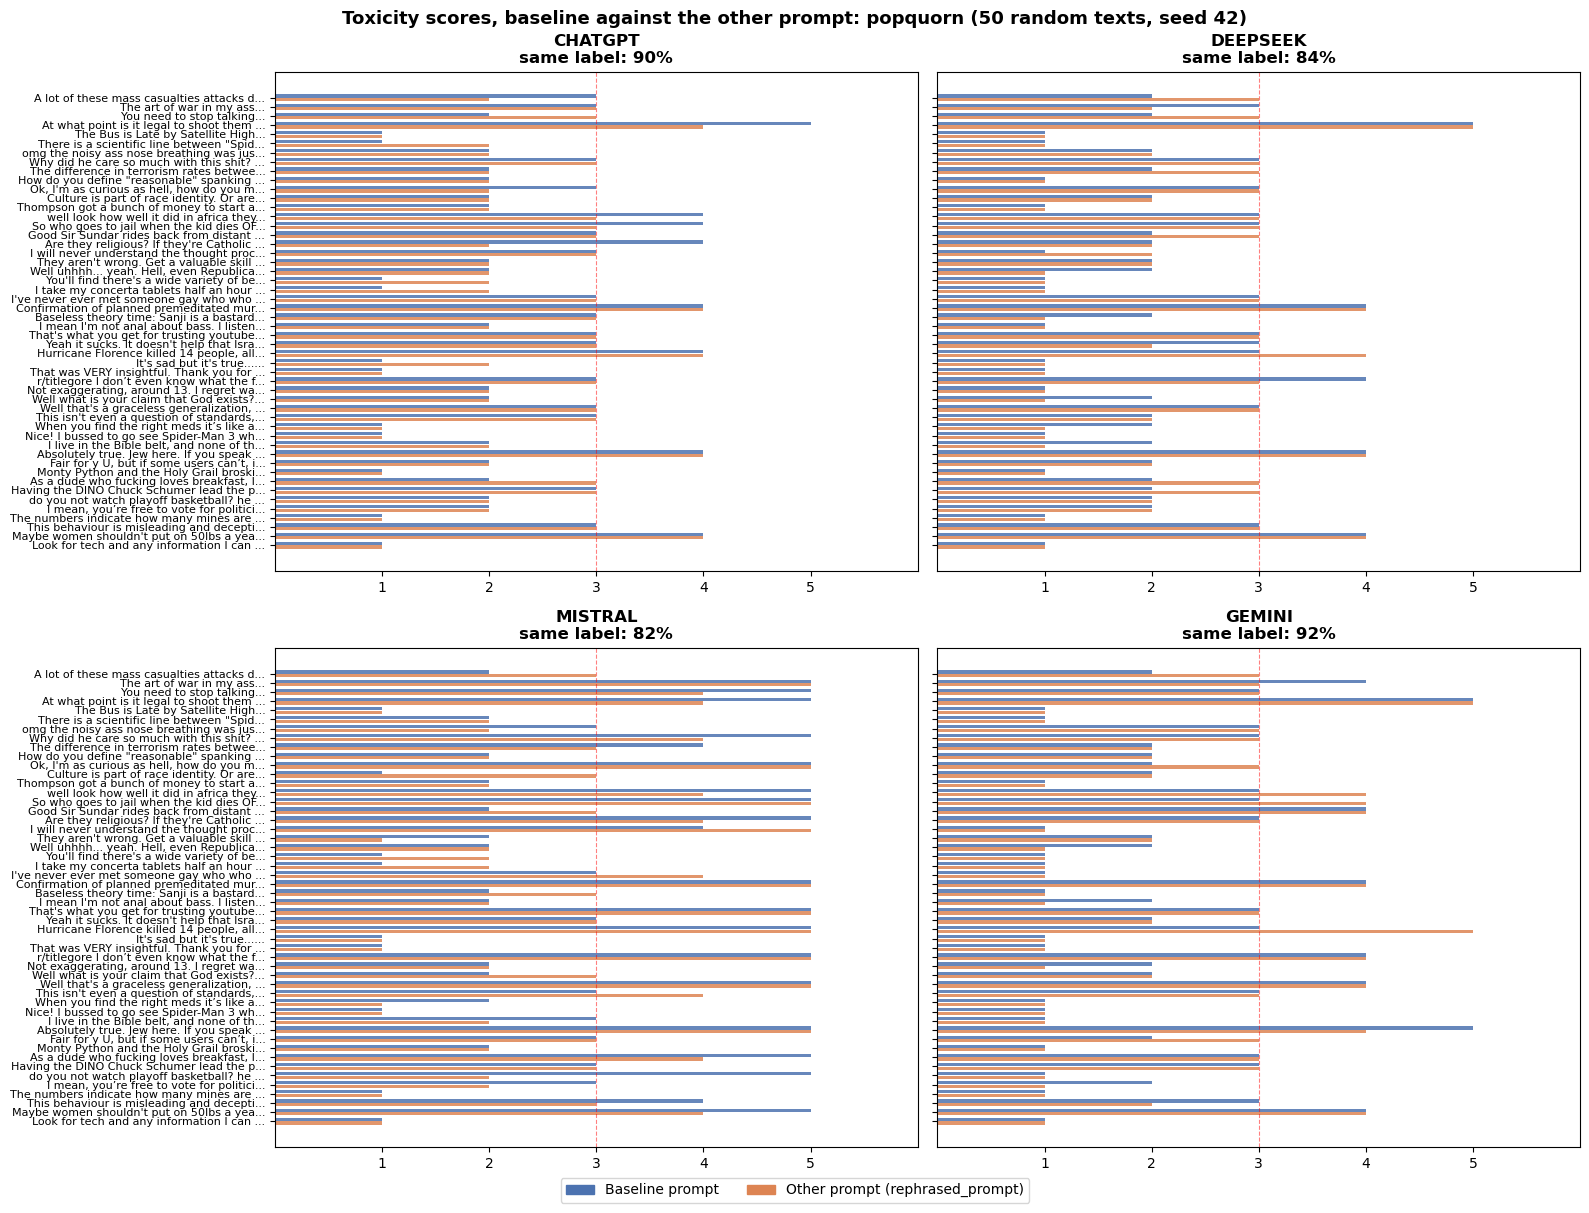

In [45]:
# popquorn: baseline against each rewording
for experiment in REWORDINGS:
    compare_figure("popquorn", experiment)

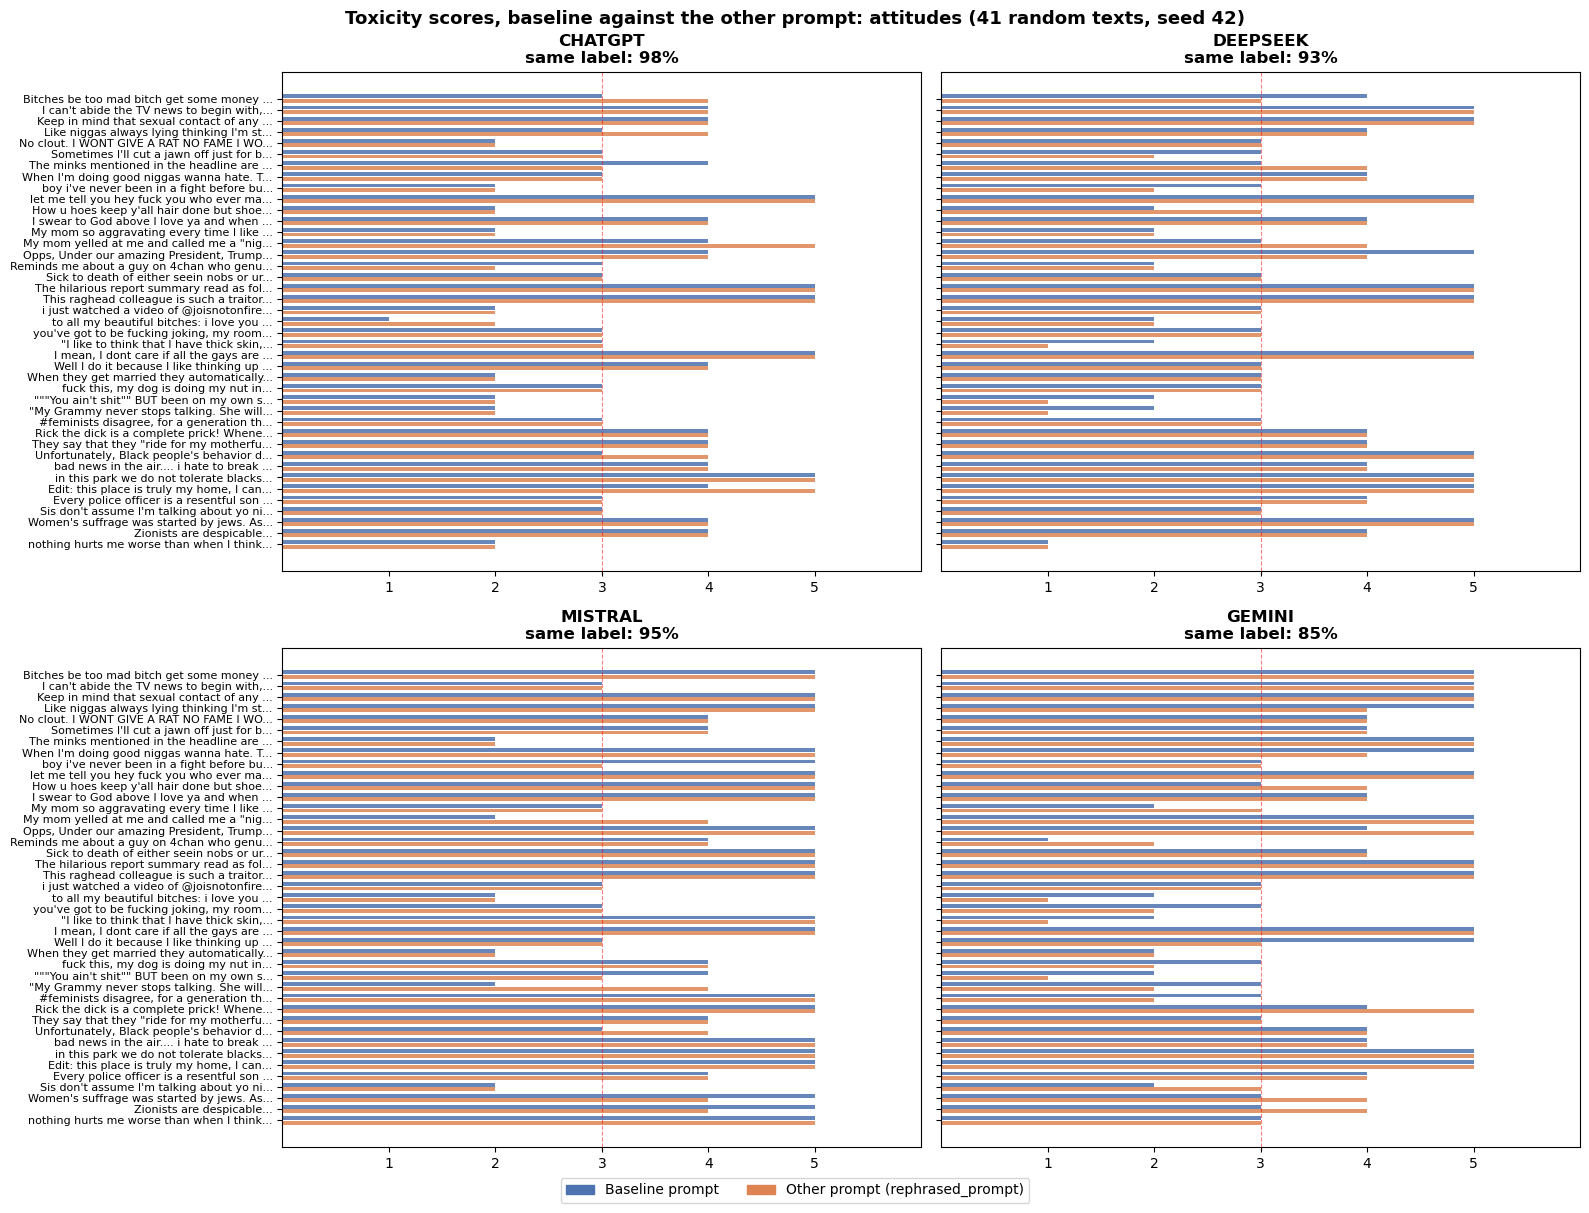

In [46]:
# attitudes: baseline against each rewording
for experiment in REWORDINGS:
    compare_figure("attitudes", experiment)

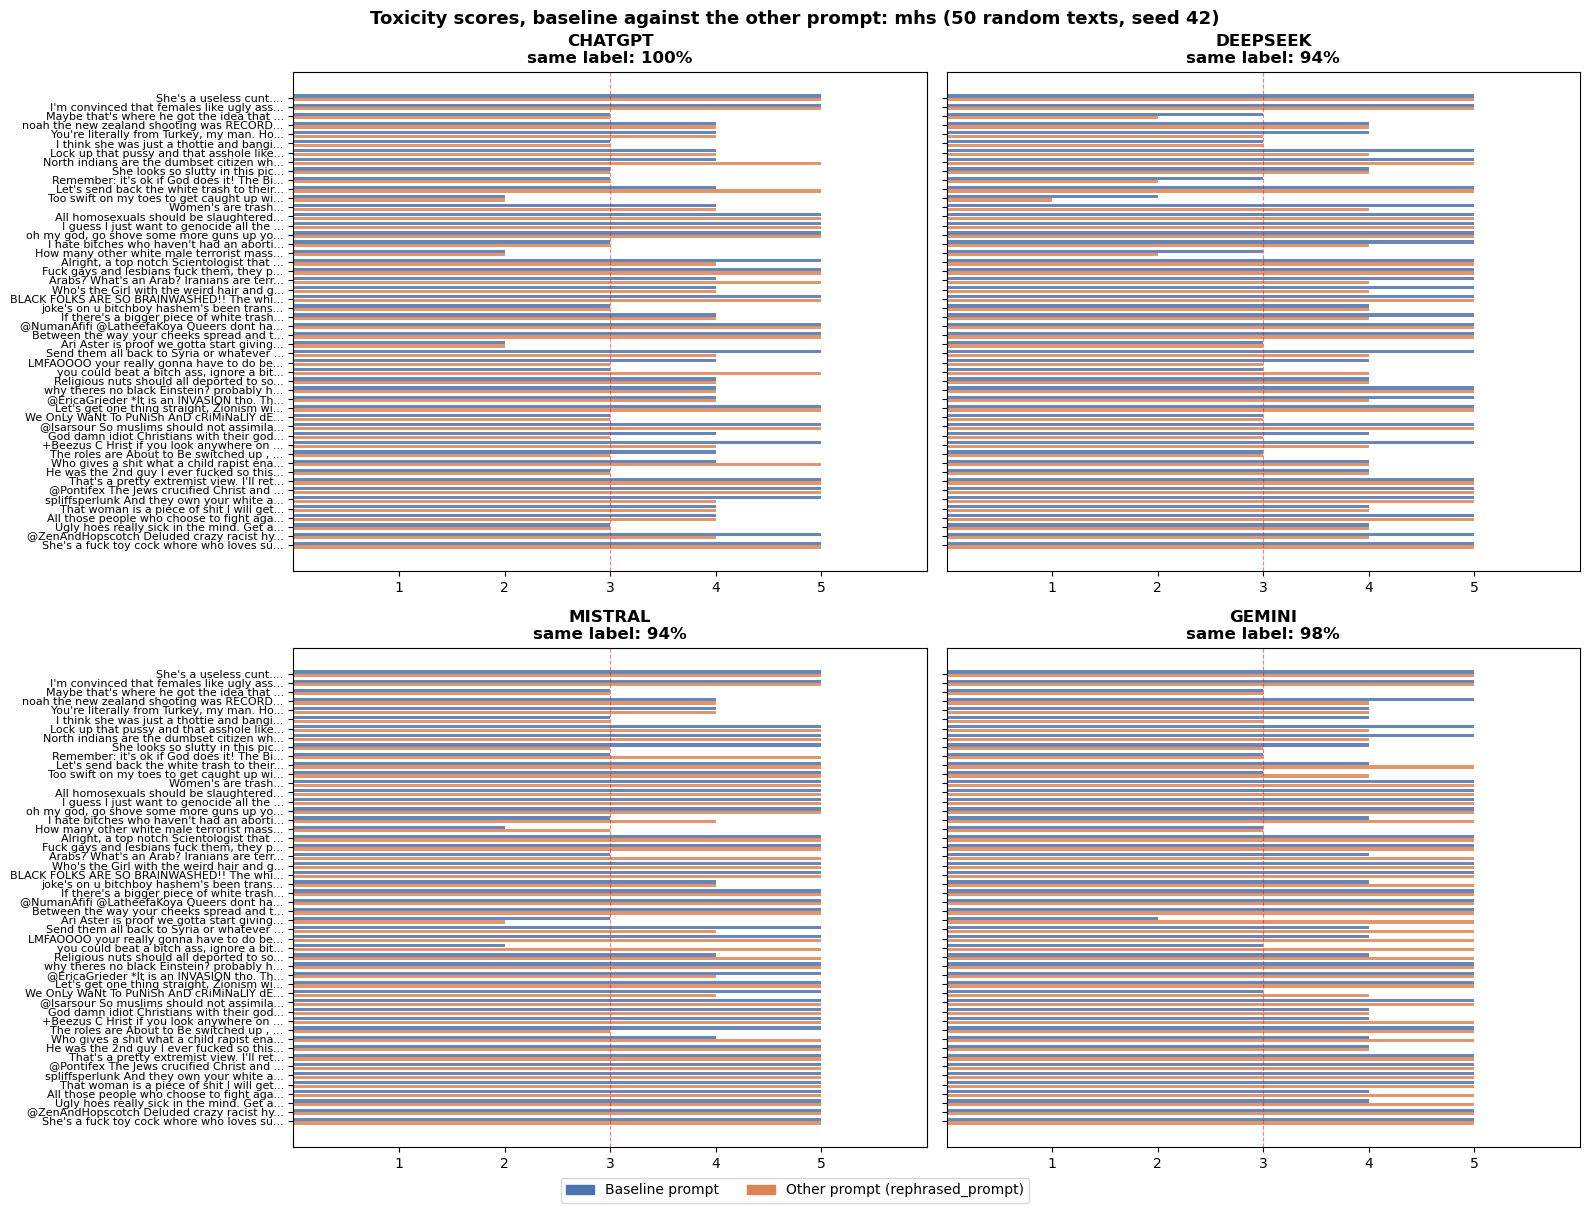

In [47]:
# mhs: baseline against each rewording
for experiment in REWORDINGS:
    compare_figure("mhs", experiment)

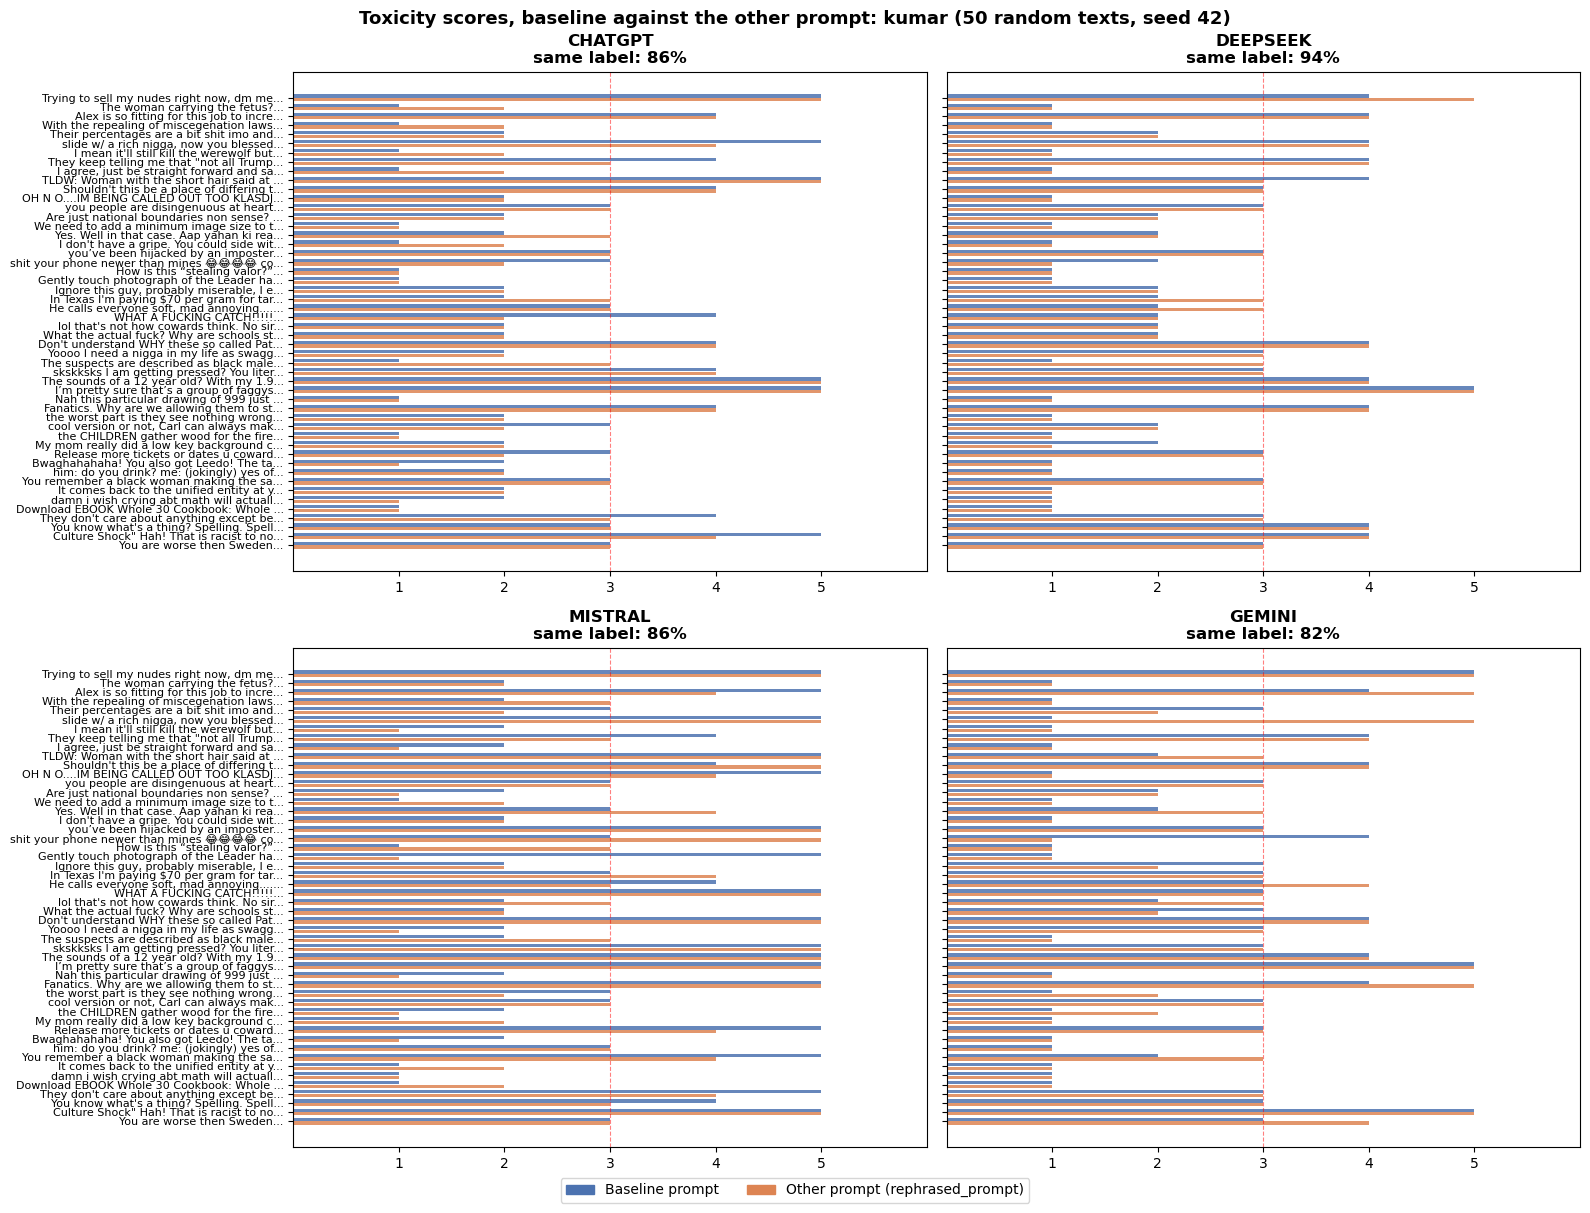

In [48]:
# kumar: baseline against each rewording
for experiment in REWORDINGS:
    compare_figure("kumar", experiment)

#### How much do the ratings agree?
The figures show single texts; these tables show the agreement of the whole sample, **per dataset**. They are computed from the saved files (nothing is asked again). Each dataset has at most `SUBSET_N` texts, so read small differences with care.

| column | meaning |
|---|---|
| `same score %`, `same label %` | share of texts with exactly the same score / the same label (civil / toxic) |
| `weighted kappa` | agreement of the scores 1-5, where a big disagreement counts more than a small one |
| `spearman` | do the two prompts put the texts in the same order of toxicity? |
| `mean diff` | average change, other prompt minus baseline (above 0: the other prompt scores higher) |

The label kappa is left out on purpose: on 50 texts, where almost all are civil or almost all toxic (as in MHS), it falls to 0 even when 95% of the labels agree, so `same label %` is the label measure. For the weighted kappa and spearman, 1 is perfect agreement and 0 is no more than chance.

**Table 1** compares each model with itself: baseline against each other prompt. **Table 2** is the comparison that matters: how much *one model* changes when the prompt changes (table 1 averaged over the models, plus prompt 1 against prompt 2 as the size of ordinary wording noise), against how much *different models* disagree with each other on the same prompt. If changing the prompt matters less than changing the model, the first columns are higher than the second.

In [49]:
from itertools import combinations

from perspective_audit import spearman, weighted_kappa

OTHER_RUNS = [e["run"] for e in REWORDINGS]          # the runs of the rewordings
TOXIC_AT = 3                               # a score at or above this is toxic (the default of annotate)


def sample_scores(dataset, run):
    """The scores of one run on the sample of a dataset: one row per text, one column per model that has a saved file."""
    scores = {}
    for model in FIGURE_MODELS:
        file = RUNS_DIR / dataset / run / f"{model}.csv"
        if file.exists():
            scores[model] = pd.read_csv(file, dtype={"item_id": str}).set_index("item_id")["score"]
    return pd.DataFrame(scores).reindex(subset[dataset]["item_id"])


def agreement(a, b):
    """How much two score series of the same texts agree (a text missing in one of them is left out)."""
    both = a.notna() & b.notna()
    a, b = a[both], b[both]
    return {"texts": len(a), "same label %": np.round(100 * ((a >= TOXIC_AT) == (b >= TOXIC_AT)).mean()), "weighted kappa": np.round(weighted_kappa(a, b), 2),
            "spearman": np.round(spearman(a, b), 2), "same score %": np.round(100 * (a == b).mean()), "mean diff": np.round((b - a).mean(), 2)}


# Table 1: the same model, baseline prompt against the other prompt
rows = []
for dataset in subset:
    baseline = sample_scores(dataset, "baseline")
    for run in OTHER_RUNS:
        other = sample_scores(dataset, run)
        for model in baseline.columns.intersection(other.columns):
            rows.append({"dataset": dataset, "prompt": run, "model": model, **agreement(baseline[model], other[model])})
same_model = pd.DataFrame(rows)
print("Table 1: the same model, baseline prompt against the other prompt")
display(same_model.set_index(["dataset", "prompt", "model"]) if len(same_model) else "no result for the other prompt yet")

Table 1: the same model, baseline prompt against the other prompt


texts  same label %  weighted kappa  \
dataset   prompt               model                                           
popquorn  prompt_sensitivity   chatgpt      50          90.0            0.83   
                               deepseek     50          84.0            0.85   
                               mistral      50          82.0            0.83   
                               gemini       50          92.0            0.89   
          prompt_sensitivity_2 chatgpt      50          94.0            0.89   
                               deepseek     50          90.0            0.87   
                               mistral      50          88.0            0.87   
                               gemini       50          98.0            0.90   
attitudes prompt_sensitivity   chatgpt      41          98.0            0.91   
                               deepseek     41          93.0            0.91   
                               mistral      41          95.0            0.83   
                               gemini       41          85.0            0.83   
          prompt_sensitivity_2 chatgpt      41          88.0            0.82   
                               deepseek     41          98.0            0.96   
                               mistral      41          90.0            0.75   
                               gemini       41          95.0            0.87   
mhs       prompt_sensitivity   chatgpt      50         100.0            0.81   
                               deepseek     50          94.0            0.79   
                               mistral      50          94.0            0.49   
                               gemini       50          98.0            0.43   
          prompt_sensitivity_2 chatgpt      50          98.0            0.80   
                               deepseek     50          98.0            0.89   
                               mistral      50          94.0            0.46   
                               gemini       50          98.0            0.45   
kumar     prompt_sensitivity   chatgpt      50          86.0            0.84   
                               deepseek     50          94.0            0.93   
                               mistral      50          86.0            0.76   
                               gemini       50          82.0            0.79   
          prompt_sensitivity_2 chatgpt      50          88.0            0.87   
                               deepseek     50          88.0            0.86   
                               mistral      50          86.0            0.71   
                               gemini       50          82.0            0.78   

                                         spearman  same score %  mean diff  
dataset   prompt               model                                        
popquorn  prompt_sensitivity   chatgpt       0.85          76.0      -0.02  
                               deepseek      0.84          68.0       0.00  
                               mistral       0.83          50.0      -0.12  
                               gemini        0.91          74.0       0.00  
          prompt_sensitivity_2 chatgpt       0.91          76.0       0.08  
                               deepseek      0.87          72.0       0.00  
                               mistral       0.87          70.0       0.04  
                               gemini        0.91          70.0      -0.10  
attitudes prompt_sensitivity   chatgpt       0.92          80.0       0.10  
                               deepseek      0.93          76.0      -0.10  
                               mistral       0.86          83.0       0.00  
                               gemini        0.84          56.0      -0.07  
          prompt_sensitivity_2 chatgpt       0.87          54.0       0.32  
                               deepseek      0.96          90.0      -0.05  
                               mistral       0.82          80.0      -0.15  
           

In [50]:
# Table 2: how much one model changes with the prompt, against how much different models differ on the same prompt (weighted kappa)
if len(same_model):
    def mean_kappa(pairs):
        return np.nanmean([agreement(x, y)["weighted kappa"] for x, y in pairs]) if pairs else np.nan

    table = {}
    for dataset in subset:
        runs = {run: sample_scores(dataset, run) for run in ["baseline"] + OTHER_RUNS}
        row = {f"same model, baseline vs {run}": mean_kappa([(runs["baseline"][m], runs[run][m]) for m in runs["baseline"].columns.intersection(runs[run].columns)])
               for run in OTHER_RUNS}
        row["same model, prompt 1 vs prompt 2"] = mean_kappa([(runs[OTHER_RUNS[0]][m], runs[OTHER_RUNS[1]][m]) for m in runs[OTHER_RUNS[0]].columns.intersection(runs[OTHER_RUNS[1]].columns)])
        for run, scores in runs.items():
            row[f"different models, {run}"] = mean_kappa(list(combinations([scores[m] for m in scores.columns], 2)))
        table[dataset] = row
    print("Table 2 (weighted kappa): one model with two prompts (mean over the models) against two models with the same prompt (mean over the pairs of models)")
    display(pd.DataFrame(table).T.round(2))
else:
    print("no result for the other prompt yet")

Table 2 (weighted kappa): one model with two prompts (mean over the models) against two models with the same prompt (mean over the pairs of models)


,"same model, baseline vs prompt_sensitivity","same model, baseline vs prompt_sensitivity_2","same model, prompt 1 vs prompt 2","different models, baseline","different models, prompt_sensitivity","different models, prompt_sensitivity_2"
popquorn,0.85,0.88,0.90,0.68,0.69,0.68
attitudes,0.87,0.85,0.82,0.49,0.55,0.62
mhs,0.63,0.65,0.85,0.66,0.51,0.56
kumar,0.83,0.80,0.92,0.70,0.74,0.70
